# Ablation study for sliding windows

This tutorials shows how to set up an multiple slide molecular cartography dataset used from [Legnini et al., 2023](https://doi.org/10.1038/s41592-023-01986-w). To follow along with this and the following tutorials, please execute the following steps first:

- Set up InterScale environment (see instructions in ReadMe)
- Download the sample data from the original publication from [Zenodo](https://doi.org/10.5281/zenodo.6143560) under the accession no. 6143561

In [1]:
import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import issparse
import seaborn as sns
from scipy.sparse import csr_array, csr_matrix, issparse
import interscale

from pathlib import Path

import warnings
warnings.filterwarnings('ignore')

In [2]:
import os

# LRZ home
if os.path.exists("/dss/dsshome1/05/di93tig"):
    print('LRZ cluster')
    CLUSTER = 'LRZ'
    BASE_DIR_REPO = "/dss/dsshome1/05/di93tig/1_projects" 
    BASE_DIR_PROJECT = "/dss/dssfs03/tumdss/pn36po/pn36po-dss-0002/di93tig/Projects/A3_InterScale"
elif os.path.exists("/home/icb/francesca.drummer/"):
    print('HPC cluster')
    CLUSTER = 'HPC'
    BASE_DIR_REPO = "/home/icb/francesca.drummer/1-Projects/A3_InterScale/InterScale_reproducibility/"
    BASE_DIR_PROJECT = "/lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/"
else:
    print('unkown')
    CLUSTER = 'unknown'
DATA = "legnini23"

HPC cluster


In [3]:
import yaml
with open(os.path.join(BASE_DIR_REPO, "figures/config.yml"), "r") as f:
    config = yaml.safe_load(f)

PALETTE = config["palettes"]["continuous"]
#CELL_TYPE_COLORS = config["palettes"][DATA]

slides = config["slide_examples"]["legnini23"]

<mark>TODO: Change data path</mark>

In [4]:
LRZ_LEGNINI23 = f'{BASE_DIR_PROJECT}/data/{DATA}.h5ad'  

## Load data

In [5]:
adata = sc.read_h5ad(LRZ_LEGNINI23)
adata

AnnData object with n_obs × n_vars = 43762 × 88
    obs: 'Cell', 'Area', 'x', 'y', 'sample', 'condition', 'organoid', 'obs_names', 'split'
    var: 'gene_ids', 'feature_types'
    obsm: 'spatial'
    layers: 'log1p_norm', 'norm_ftsqrt', 'raw', None (.X)

In [6]:
print('Zero count cells: ', (adata.X.sum(1) ==0).sum())

Zero count cells:  648


In [7]:
# only needed when re-running on an adata that already carries the zones
adata.obs.drop(columns=["SHH_zone"], errors="ignore", inplace=True)

In [8]:
from interscale.tl import clustering

# The last edge is open-ended on purpose. create_spatial_cluster_distance bins
# dist_to_SHH with pd.cut, so any cell beyond the last edge becomes NaN in
# SHH_zone. With a closed edge at 6000 that silently dropped 685 cells of
# slide1_C2-2 (dist_to_SHH 6000-8034, the only slide reaching that far), and the
# NaN propagated into sliding_window_low -> scvi's CategoricalObsField assigns
# code -1 and register_fields dies with
#   ValueError: Making .obs["sliding_window_low"] categorical failed.
# np.inf puts that tail into 'far', where it belongs, and keeps 4 rings.
ring_edges  = [0, 200, 2000, 3000, np.inf]
ring_labels = ['SHH', 'near', 'medium', 'far']

clustering.create_spatial_cluster_distance(
    adata, 'SHH', 'sample',
    distance_bins=ring_edges,
    bin_labels=ring_labels,
    threshold=95,
)

AnnData object with n_obs × n_vars = 43762 × 88
    obs: 'Cell', 'Area', 'x', 'y', 'sample', 'condition', 'organoid', 'obs_names', 'split', 'dist_to_SHH', 'SHH_zone'
    var: 'gene_ids', 'feature_types'
    obsm: 'spatial'
    layers: 'log1p_norm', 'norm_ftsqrt', 'raw', None (.X)

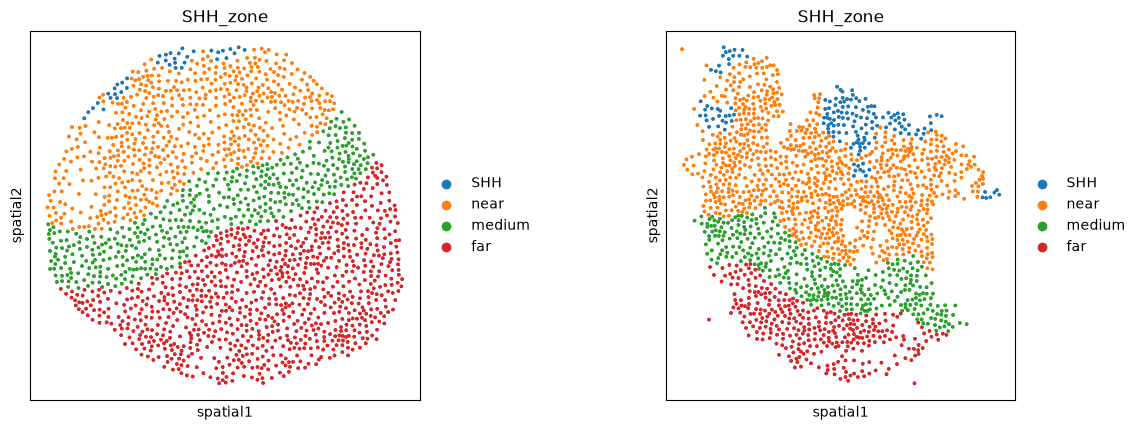

In [9]:
sq.pl.spatial_scatter(
    adata[adata.obs['sample'].isin([slides["Ctrl"], slides["SSH"]])],
    spatial_key = 'spatial',
    library_key='sample', 
    #library_id = [839, 6],
    color="SHH_zone", #cell_type_coarse",
    shape= None,
    size = 10,
)

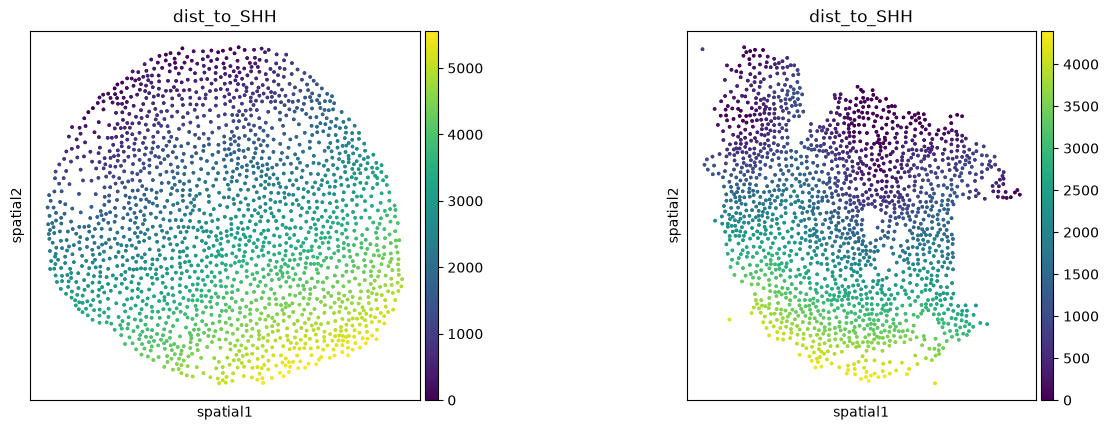

In [10]:
sq.pl.spatial_scatter(
    adata[adata.obs['sample'].isin([slides["Ctrl"], slides["SSH"]])],
    spatial_key = 'spatial',
    library_key='sample', 
    #library_id = [839, 6],
    color="dist_to_SHH", #cell_type_coarse",
    shape= None,
    size = 10,
)

Check that no NaN's exists in the data.

In [11]:
# dropna=False: a plain groupby().size() hides exactly the NaNs this checks for
print(adata.obs["SHH_zone"].value_counts(dropna=False))
assert adata.obs["SHH_zone"].isna().sum() == 0, (
    "cells outside every ring - widen ring_edges (the last edge must cover max(dist_to_SHH))"
)

SHH_zone
near          25023
medium         9043
far            8110
SHH            1586
No_Source         0
Background        0
Name: count, dtype: int64


## Load trained models

In [12]:
import sys

project_root = Path(BASE_DIR_REPO)  # InterScale_reproducibility, for `from src.wandb import ...`
sys.path.insert(0, str(project_root))

# The interscale package is a SIBLING of InterScale_reproducibility, not a subdirectory of it, so
# `Path(BASE_DIR_REPO) / "interscale"` points at nothing here. It only resolved in
# 3_sliding_window_ablation.ipynb, where BASE_DIR_REPO is the A3_InterScale root.
INTERSCALE_REPO = project_root.parent / "interscale"
REGISTRY = INTERSCALE_REPO / "config_files" / "registry.yaml"

DATASET = "legnini23"

# ---------------------------------------------------------------------------------------------
# WHICH MASKING ARM TO LOAD.  Flip this and re-run from here; nothing below is arm-specific.
#
#   "cell"  whole cells are blanked and all G genes of them are scored  (mask_strategy "node")
#   "gene"  individual (cell, gene) entries are blanked and only those are scored
#
# The two sweeps below are matched: same five seeds, same 300 epochs, same architecture, and both
# trained with MASK_VALUE = -1. They differ only in masking granularity and its rate, so a
# difference in how stable the gene loadings are across seeds is attributable to that.
#
# The rate is not the same number in the two arms because it is not the same quantity: 0.30 of
# the CELLS vs 0.25 of every cell's GENES. 0.25 is where gene masking measurably wins
# (val_concordance_corr 0.1947 +/- 0.0041 against cell 0.30's 0.1634 +/- 0.0084, 3 seeds).
#
# NOTE these are NOT the published seed_stability/ models. Those were trained at the old 100-epoch
# default with MASK_VALUE = 0 and are left untouched in `.../legnini23_revision/seed_stability/`.
# 300 epochs because at 100 no trial on this dataset ever early-stops (optim.min_delta is 0.0, so
# only the n_epochs cap stops a run) and 100 -> 300 moves val_concordance_corr by +200% to +286%;
# seed spread is 2-18% at 100 and 1-4% at 300, so a stability analysis at 100 would largely be
# measuring undertraining.
# ---------------------------------------------------------------------------------------------
MASKING = "cell"  # "cell" | "gene"

ARMS = {
    "cell": {
        "task": "node_reg",
        "sweep_id": "ze40fzaz",  # config_files/sweeps/seed_cell_masking.yaml
        "models_subdir": "seed_stability_cell",
        # Nothing to override: node_reg's registry defaults are what the sweep trained with.
        "overrides": {},
    },
    "gene": {
        "task": "node_reg_genemask",
        "sweep_id": "dty3dlk3",  # config_files/sweeps/seed_gene_masking.yaml
        "models_subdir": "seed_stability_gene",
        # The sweep pinned the rate below the task file's 0.5; build_cfg has to reapply it or the
        # config recorded here is not the one that trained. (It changes no tensor shape, so
        # loading would succeed either way -- which is exactly why it would go unnoticed.)
        "overrides": {"dataset.mask_percentage": 0.25},
    },
}
assert MASKING in ARMS, f"MASKING must be one of {sorted(ARMS)}"
ARM = ARMS[MASKING]
TASK, SWEEP_ID = ARM["task"], ARM["sweep_id"]

MODELS_DIR = Path(BASE_DIR_PROJECT) / "results" / "legnini23_revision" / ARM["models_subdir"]
# Per-arm, so the two arms' per-gene CSVs can sit side by side instead of overwriting each other.
RESULTS_DIR = Path(BASE_DIR_PROJECT) / "results" / DATA / f"rec_seed_stablity_{MASKING}"

assert REGISTRY.exists(), f"registry not found: {REGISTRY}"
assert MODELS_DIR.exists(), (
    f"checkpoint dir not found: {MODELS_DIR}\n"
    f"Train it with:  SWEEP_ID={SWEEP_ID} sbatch scripts/run.sh {DATASET} {TASK} "
    f"--sweep_cfg config_files/sweeps/seed_{MASKING}_masking.yaml --sweep_goal robustness --count 5"
)
print(f"masking     {MASKING} (task {TASK}, sweep {SWEEP_ID})")
print(f"registry    {REGISTRY}\ncheckpoints {MODELS_DIR}\nresults     {RESULTS_DIR}")


masking     cell (task node_reg, sweep ze40fzaz)
registry    /home/icb/francesca.drummer/1-Projects/A3_InterScale/interscale/config_files/registry.yaml
checkpoints /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/legnini23_revision/seed_stability_cell
results     /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/legnini23/rec_seed_stablity_cell


In [13]:
import os
from pathlib import Path

import wandb

from interscale.evaluation import plot_global_directionality
from interscale.evaluation.net_streams import compute_hierarchical_net_flow
from interscale.tl.utils import set_full_reproducibility
from src.wandb import Wandb_evaluation, plot_f1_across_seeds

# Everything that used to be defined inline in this notebook now lives in
# src/decoder_stability.py, so that notebooks/Cosmx/4_decoder_stability_cosmx.ipynb runs the
# SAME selection code rather than a copy of it. The two notebooks are meant to be a
# like-for-like comparison of loading stability across two datasets, and that only holds if
# the gene-selection code is literally shared.
#
# `expected_intersection` used to be imported from interscale.tl.utils, where it does not
# exist -- it lives in src/utils.py, now next to `intersection_tail_probability`, which
# `tail_prob_by_k` needs and which this notebook previously relied on being left in the
# kernel by a cell that has since been deleted. Both are re-exported here.
from src.decoder_stability import (
    GROUP_COLORS,
    build_cfg as _build_cfg,
    collect_gene_sets,
    expected_intersection,
    intersection_by_k,
    intersection_tail_probability,
    local_global_split,
    overlap_matrix,
    per_gene_metrics,
    plot_intersection_by_k,
    plot_membership,
    plot_tail_prob_by_k,
    run_seed_inference,
    tail_prob_by_k,
)

wandb.login()

wandb: ERROR Failed to detect the name of this notebook. You can set it manually with the WANDB_NOTEBOOK_NAME environment variable to enable code saving.
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /home/icb/francesca.drummer/.netrc.
wandb: Currently logged in as: francesca-drummer to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

## Load WandB sweep

Load sweep from WandB (5 seeds, all the same model parameters)

In [14]:
# NOT `wandb = ...`: that name is the wandb module, imported two cells up, and rebinding it is
# what made `wandb.Api(timeout=60)` raise AttributeError further down.
#
# SWEEP_ID comes from the MASKING switch above. The first argument is only a label --
# Wandb_evaluation hardcodes entity/project to francesca-drummer/InterScale_hyperparameter_sweep.
sweep_eval = Wandb_evaluation(
    "InterScale",
    SWEEP_ID,
    local_component=True,
    global_component=True,
    sweep_goal="robustness",
    classes=[None],
)


In [15]:
sweep_df = sweep_eval.get_dataframe()
sweep_df.head()

,id,name,seed,state,mask_percentage,mask_strategy,pct_mask_nodes,radius,decoder_type,runtime_seconds,total_parameters,test_r2,test_pearson_corr
0,t3cxaxb3,dual_legnini23_regr_node_40_GCN_self-attn-tran...,40,finished,0.3,node,0.3,None,None,153,51168,-1.386118,0.312122
1,phmtuc86,dual_legnini23_regr_node_41_GCN_self-attn-tran...,41,finished,0.3,node,0.3,None,None,252,51168,-0.682518,0.326741
2,9p9ixuw9,dual_legnini23_regr_node_42_GCN_self-attn-tran...,42,finished,0.3,node,0.3,None,None,238,51168,-0.278964,0.335235
3,lshqnbqa,dual_legnini23_regr_node_43_GCN_self-attn-tran...,43,finished,0.3,node,0.3,None,None,256,51168,-0.259736,0.345807
4,rjo32qaa,dual_legnini23_regr_node_44_GCN_self-attn-tran...,44,finished,0.3,node,0.3,None,None,233,51168,-0.294231,0.350113


## Model inference

Load each of the five seed models, run inference, and keep

- `local_emb[seed]` / `global_emb[seed]` &mdash; the two embeddings, `(n_cells, n_embed)`
- `models[seed]` &mdash; the loaded `CombinedModel`, for the gene-loading section below
- `performance[seed]` &mdash; per-gene reconstruction scores, also written to
  `results/legnini23/rec_seed_stablity/model_{seed}_performance.csv`

The models are loaded from disk rather than from wandb artifacts: the sweep pinned `model.save`,
so all five checkpoints already sit in `legnini23_revision/seed_stability/`.

**The seed cannot be read off `run.config['optim']['seed']`.** `main_sweep.py` calls
`wandb.init(config=cfg)` *before* `apply_sweep_config`, so the nested config wandb stored is the
base config &mdash; seed 44 for all five runs, which is also why every run is named `..._44_...`.
Only the flattened `run.config['optim.seed']` (what `sweep_df["seed"]` reads) carries the trial's
actual value, and it is what `build_cfg` applies below.

In [16]:
from functools import partial

# `config_files/sweeps/seed_{cell,gene}_masking.yaml` declare optim.seed over [40..44], a fixed
# optim.n_epochs and model.save, and -- for the gene arm only -- a fixed
# dataset.mask_percentage. Reapplying those on top of the resolved (DATASET, TASK) pair
# reproduces the config each trial trained with; everything else (radius 200, n_embed 16,
# dual_decoder) comes from the registry, unchanged.
#
# optim.seed is not cosmetic: get_model_filename_prefix puts it in the checkpoint name, which
# is what makes the five models separable when load() picks the file. The same prefix also
# carries dataset.name, which the registry sets to legnini23_genemask for the gene arm -- so
# the two arms' checkpoints are distinguishable even before the directory split.
build_cfg = partial(
    _build_cfg,
    DATASET,
    TASK,
    REGISTRY,
    models_dir=MODELS_DIR,
    overrides={"optim.n_epochs": 300, **ARM["overrides"]},
)

# per_gene_metrics is imported from src.decoder_stability; run_seed_inference calls it.

In [17]:
from interscale.tl import remove_zero_expression_cells

# Training ran on the zero-expression-filtered adata (43762 -> 43114 cells here). Inference has to
# filter identically, or the per-sample graphs handed to the model are not the graphs it was
# trained on.
#
# remove_zero_expression_cells reads adata.X, and a cell further down repoints adata.X at
# log1p_norm -- where no cell sums to zero, so re-running this cell after that one would silently
# keep all 43762. layers['raw'] is the same matrix X holds on load (identical nnz, identical 648
# zero rows), so restoring it first makes this cell order-independent.
adata.X = adata.layers["raw"]
adata = remove_zero_expression_cells(adata)

SEEDS = sorted(sweep_df["seed"].astype(int))
print("seeds:", SEEDS)

cfg0 = build_cfg(SEEDS[0])
window_key = cfg0.dataset.sample_key[0]
assert cfg0.model.decoder.dual_decoder, (
    "cfg has no local decoder, so there is nothing to compare against the global one"
)

# Below max_seq_len, tl/padding.py random-subsamples each graph every call instead of erroring,
# so the predictions would come from a graph the model never saw.
sizes = adata.obs[window_key].value_counts()
sizes = sizes[sizes > 0]
assert sizes.max() <= cfg0.model.global_component.parameters.max_seq_len, (
    f"largest {window_key} graph is {sizes.max()} cells but max_seq_len is "
    f"{cfg0.model.global_component.parameters.max_seq_len}"
)
print(f"{len(sizes)} graphs over '{window_key}', largest {sizes.max()} cells "
      f"(max_seq_len {cfg0.model.global_component.parameters.max_seq_len})")

# Ground truth is the layer the decoders were trained to reconstruct, NOT .X -- this h5ad keeps
# counts in X (max ~120) against log1p-scale predictions (max ~4.8).
_y_true = adata.layers[cfg0.dataset.layer_key]
y_true = np.asarray(_y_true.todense() if issparse(_y_true) else _y_true, dtype=np.float64)

DECODERS = {"local": "_y_pred_local", "global": "_y_pred_global"}
# 'all' first so the csv leads with the number over every cell; the three real splits follow so
# the test rows stay comparable to the sweep's `test_r2` / `test_pearson_corr` columns.
SPLITS = ["all", "train", "val", "test"]

Nr. of zero expression cells: 648
seeds: [40, 41, 42, 43, 44]
17 graphs over 'sample', largest 4299 cells (max_seq_len 4318)


In [18]:
# Writes obsm[f"{seed}_local_emb"] / obsm[f"{seed}_global_emb"] and
# layers[f"{seed}_y_pred_local"] / layers[f"{seed}_y_pred_global"] into adata, plus one
# per-gene csv per seed under RESULTS_DIR. The seed prefix is what lets the gene-loading
# section below revisit any seed, not only the last one inferred.
adata, models, local_emb, global_emb, performance = run_seed_inference(
    adata,
    SEEDS,
    build_cfg,
    MODELS_DIR,
    RESULTS_DIR,
    y_true=y_true,
    # 40 for every model, which is what this notebook has always done. Nothing stochastic
    # happens between the load and the forward pass, so it does not change the predictions --
    # but it is stated here rather than inherited from whatever was last in scope.
    repro_seed=40,
)

Loading model from /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/legnini23_revision/seed_stability_cell/dual_legnini23_regr_node_40_GCN_self-attn-transformer_model.pt
Unclear checkpoint format. Attempting remapping anyway.
State dict remapping applied. Source detected: unknown
Load GEX from .layers/log1p_norm
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.                                                  
INFO     Creating graph using `None` transform and `1` libraries.        

## Gene loadings

In [19]:
from interscale.evaluation import (
    gene_loadings,
    calculate_gene_ranks,
    latent_rank_report,
    get_genes_dim,
    calculate_dim_importance,
)

In [20]:
adata

AnnData object with n_obs × n_vars = 43114 × 88
    obs: 'Cell', 'Area', 'x', 'y', 'sample', 'condition', 'organoid', 'obs_names', 'split', 'dist_to_SHH', 'SHH_zone', '_scvi_sample_key_0', '_scvi_split_key', '40_cls_horizontal', '40_cls_vertical', '41_cls_horizontal', '41_cls_vertical', '42_cls_horizontal', '42_cls_vertical', '43_cls_horizontal', '43_cls_vertical', '44_cls_horizontal', '44_cls_vertical'
    var: 'gene_ids', 'feature_types'
    uns: '_scvi_uuid', '_scvi_manager_uuid'
    obsm: 'spatial', '40_local_emb', '40_global_emb', '40_attn_matrix', '41_local_emb', '41_global_emb', '41_attn_matrix', '42_local_emb', '42_global_emb', '42_attn_matrix', '43_local_emb', '43_global_emb', '43_attn_matrix', '44_local_emb', '44_global_emb', '44_attn_matrix'
    layers: 'log1p_norm', 'norm_ftsqrt', 'raw', None (.X), '40_y_pred_local', '40_y_pred_global', '41_y_pred_local', '41_y_pred_global', '42_y_pred_local', '42_y_pred_global', '43_y_pred_local', '43_y_pred_global', '44_y_pred_local', '44

In [21]:
print(SEEDS, models)

[40, 41, 42, 43, 44] {40: <interscale.model.combined_model.CombinedModel object at 0x7f5d70cd5730>, 41: <interscale.model.combined_model.CombinedModel object at 0x7f5d7c66bdd0>, 42: <interscale.model.combined_model.CombinedModel object at 0x7f5d7c1c4740>, 43: <interscale.model.combined_model.CombinedModel object at 0x7f5d77ed2e40>, 44: <interscale.model.combined_model.CombinedModel object at 0x7f5d77ed2810>}


In [22]:
SEED = SEEDS[-2]

In [114]:
TRUE_LOCAL_GENES = ['DBX2', 'AGO2', 'CUX2', 'FOS', 'GLI1', 'PAX6', 'TUBB3', 'SATB2', 'DBX1', 'NKX6.1', 'ISL1', 'JUNB']
TRUE_GLOBAL_GENES = ["AC129492.1", "TBP", "VAMP2", "FOXO6", "NEUROD1", "NEUROG2", "OLIG2", "PAX7", "DBX1", "HHIP", "PER3", "POLR1B", "PROM1", "ZNF609"]

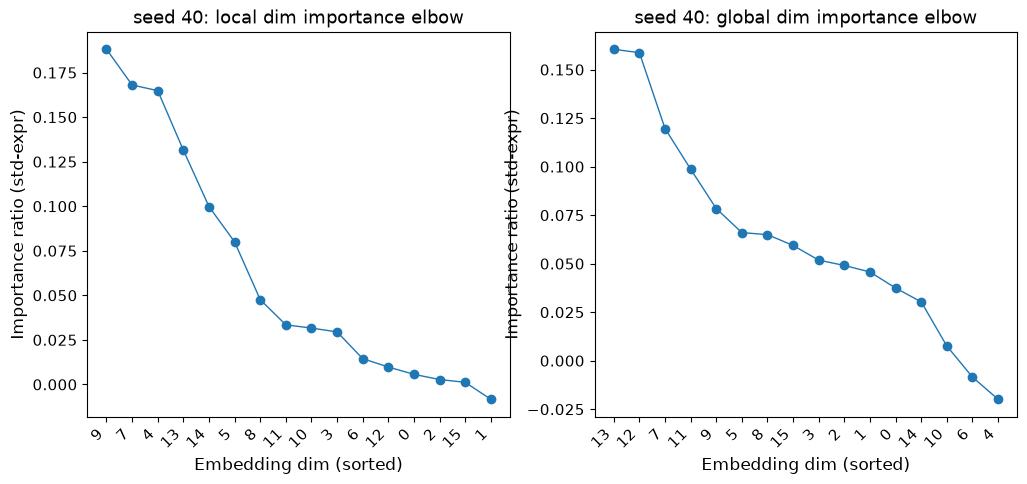

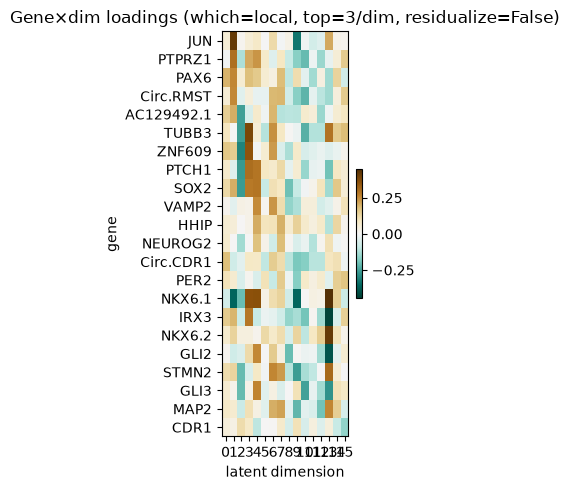

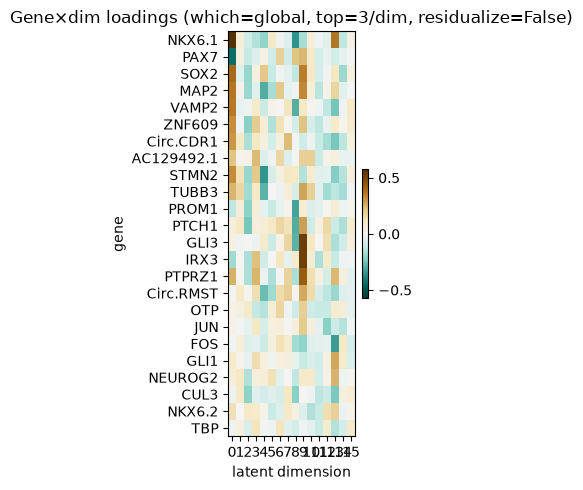

seed 40 local :  22 genes off 16 dims [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] ...
seed 40 global:  24 genes off 16 dims [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] ...


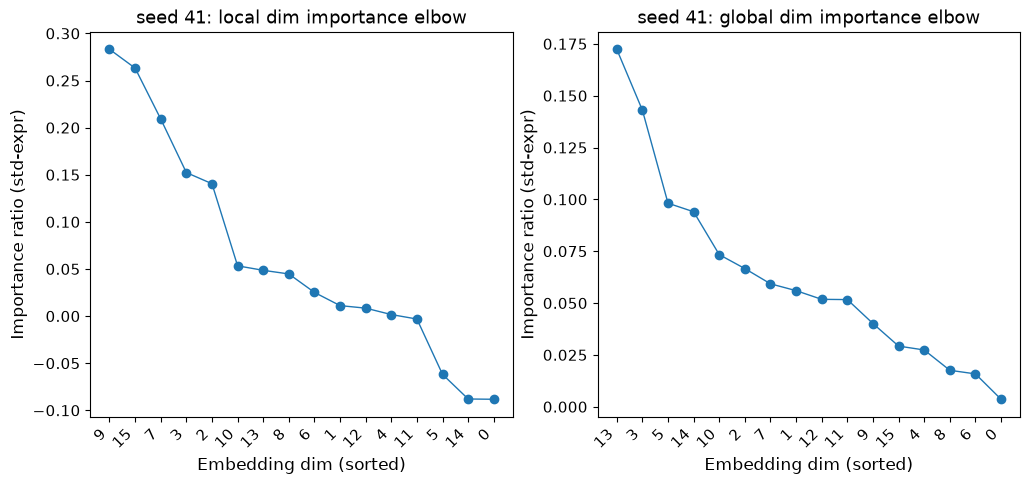

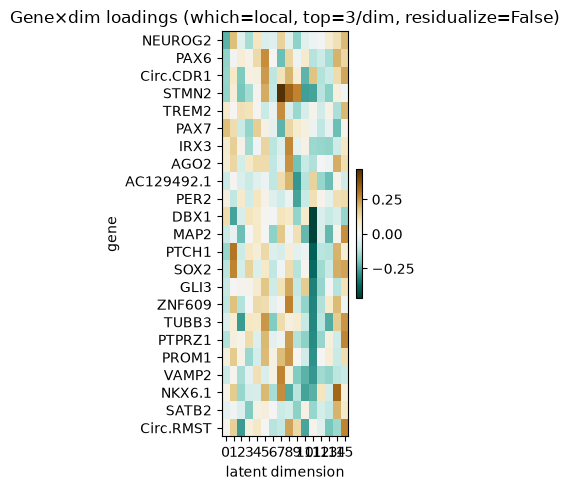

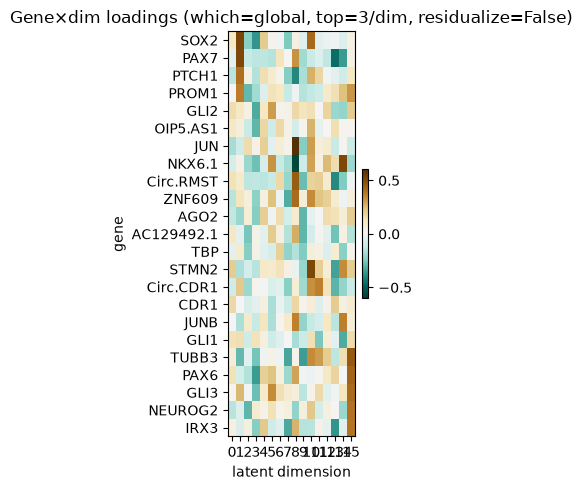

seed 41 local :  23 genes off 16 dims [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] ...
seed 41 global:  23 genes off 16 dims [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] ...


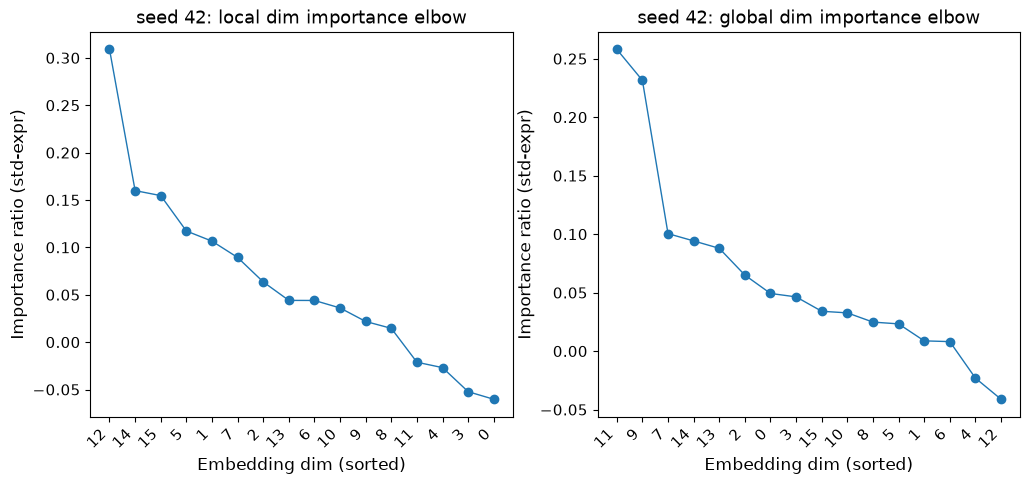

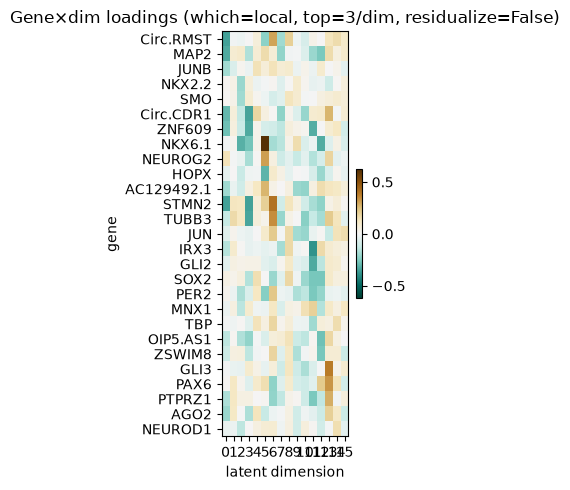

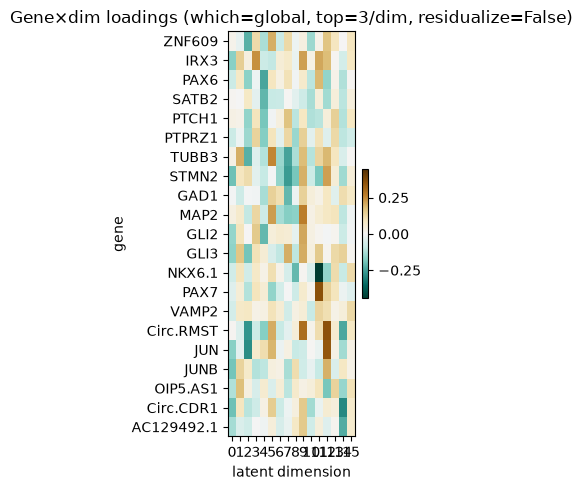

seed 42 local :  27 genes off 16 dims [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] ...
seed 42 global:  21 genes off 16 dims [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] ...


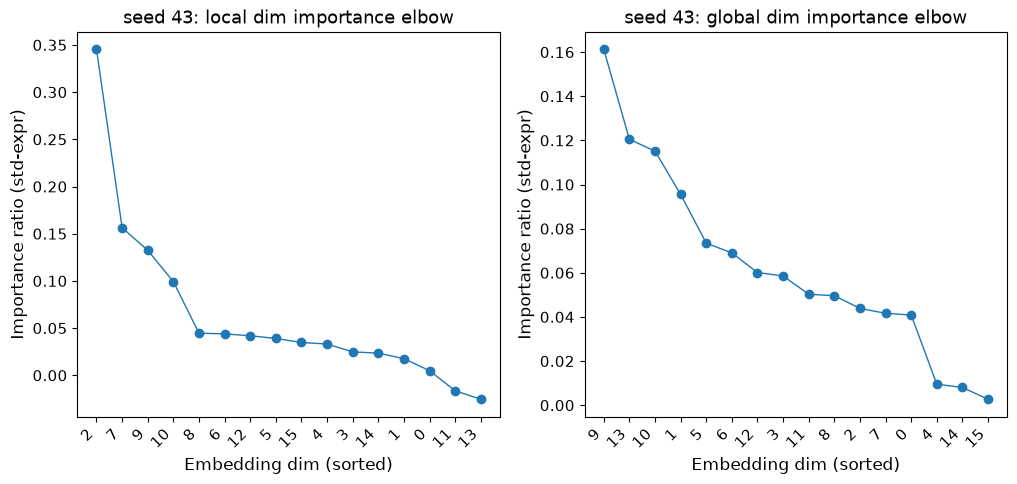

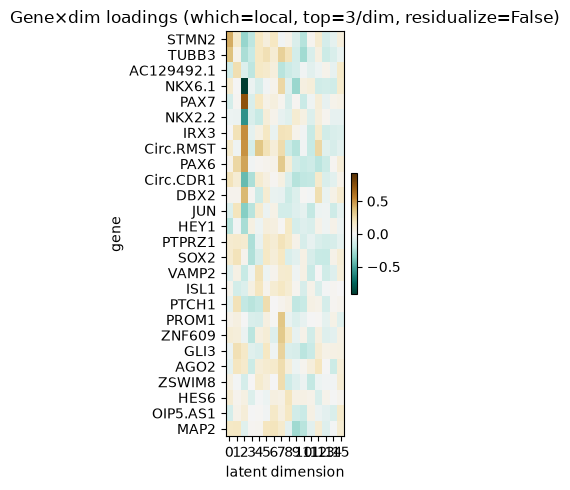

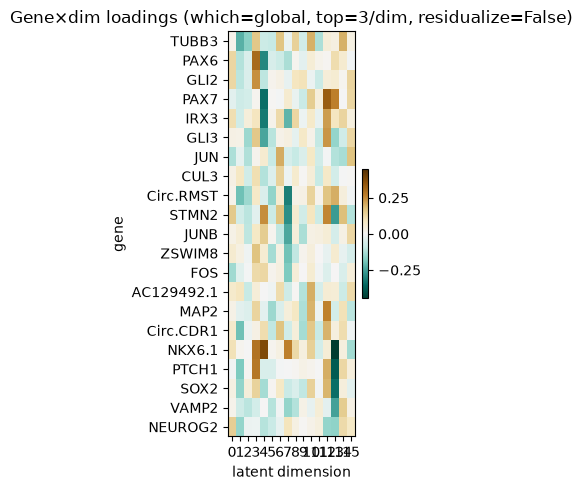

seed 43 local :  26 genes off 16 dims [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] ...
seed 43 global:  21 genes off 16 dims [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] ...


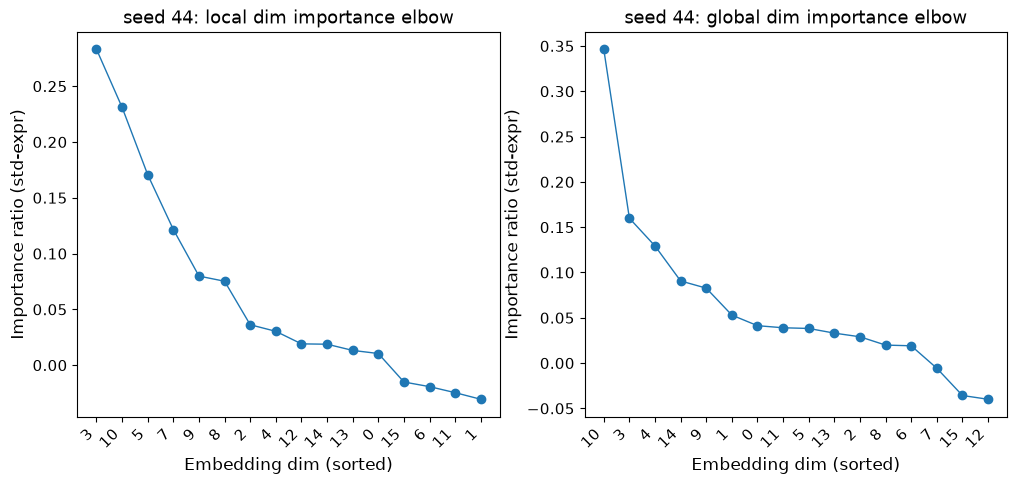

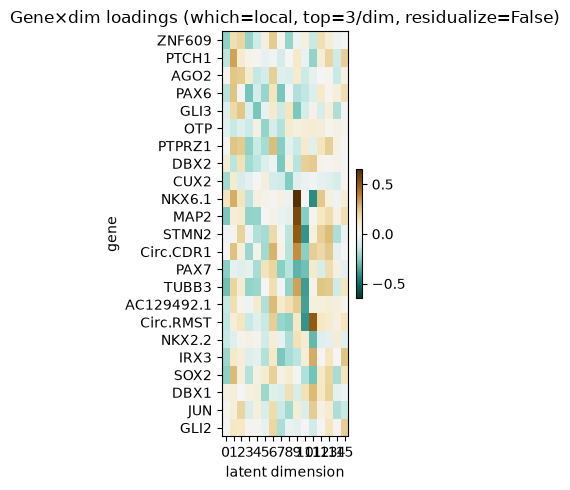

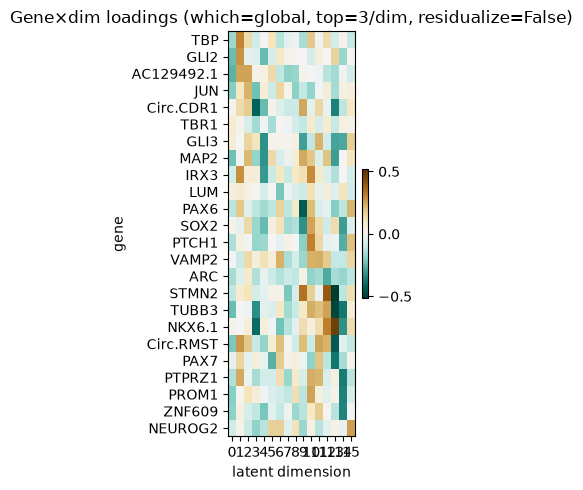

seed 44 local :  23 genes off 16 dims [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] ...
seed 44 global:  24 genes off 16 dims [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] ...


In [29]:
# NOTE this now standardizes the LOCAL loadings by the local embedding's std. The loop this
# replaces passed f"{SEED}_global_emb" as `local_latent_key`, i.e. it rescaled every local
# dimension by the wrong constant -- which changes the dimension ranking and therefore which
# genes are selected. The local gene sets below will not reproduce the previous run's.
df_local_list, df_global_list, dims_used = collect_gene_sets(
    adata,
    models,
    SEEDS,
    layer_key="log1p_norm",
    n_embed=cfg0.model.n_embed,
    # Every dimension, as before. n_embed is 16 here and the panel is 88 genes, so
    # scoring all of them is not the near-whole-panel selection it would be on CosMx
    # (n_embed 128, 979 genes) -- see collect_gene_sets' `dims` docstring.
    dims="all",
    n_top=3,
    rank_by="loading_x_sd",
    min_frac=0.0,
    enforce_specificity=False,
    specificity_min=1.5,
    cumulative_cutoff=None,
    spacing=2,
    plot=True,
)

,truth,40,41,42,43,44
NKX6.1,True,True,True,True,True,True
PAX6,True,True,True,True,True,True
TUBB3,True,True,True,True,True,True
AC129492.1,False,True,True,True,True,True
Circ.CDR1,False,True,True,True,True,True
Circ.RMST,False,True,True,True,True,True
GLI3,False,True,True,True,True,True
IRX3,False,True,True,True,True,True
MAP2,False,True,True,True,True,True
PTPRZ1,False,True,True,True,True,True


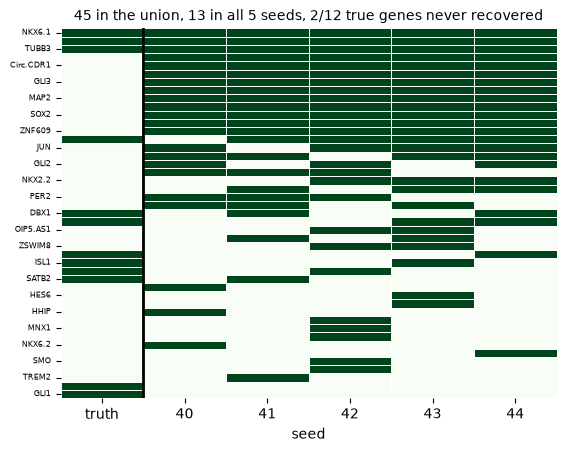

In [118]:
plot_membership(TRUE_LOCAL_GENES, df_local_list, labels=SEEDS, only_truth = False)

,truth,40,41,42,43,44
NKX6.1,True,True,True,True,True,True
PAX6,True,True,True,True,True,True
TUBB3,True,True,True,True,True,True
AGO2,True,False,True,True,True,True
DBX1,True,False,True,False,False,True
DBX2,True,False,False,False,True,True
CUX2,True,False,False,False,False,True
ISL1,True,False,False,False,True,False
JUNB,True,False,False,True,False,False
SATB2,True,False,True,False,False,False


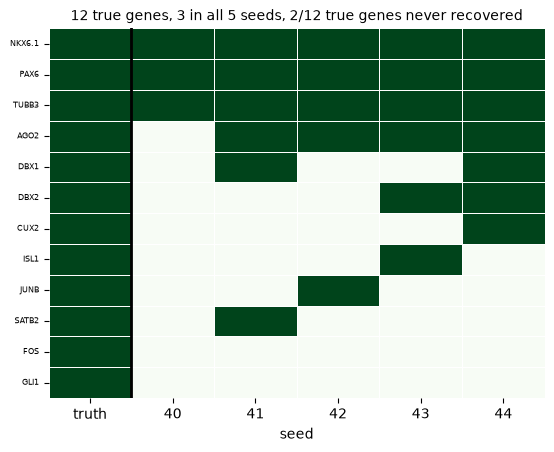

In [119]:
plot_membership(TRUE_LOCAL_GENES, df_local_list, labels=SEEDS, only_truth = True)

,truth,40,41,42,43,44
AC129492.1,True,True,True,True,True,True
PAX7,True,True,True,True,True,True
Circ.CDR1,False,True,True,True,True,True
Circ.RMST,False,True,True,True,True,True
GLI3,False,True,True,True,True,True
IRX3,False,True,True,True,True,True
JUN,False,True,True,True,True,True
NKX6.1,False,True,True,True,True,True
PTCH1,False,True,True,True,True,True
STMN2,False,True,True,True,True,True


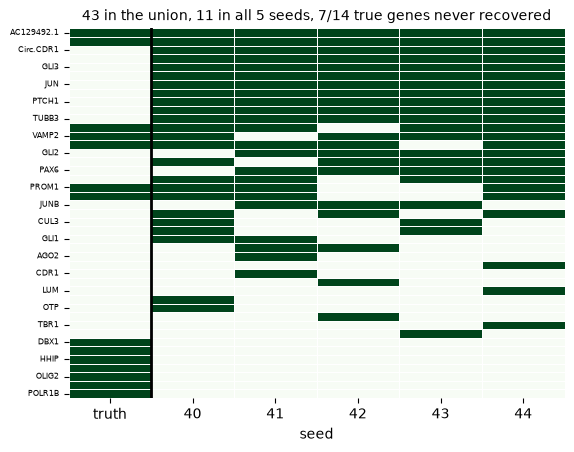

In [120]:
plot_membership(TRUE_GLOBAL_GENES, df_global_list, labels=SEEDS, only_truth = False)

,truth,40,41,42,43,44
AC129492.1,True,True,True,True,True,True
PAX7,True,True,True,True,True,True
NEUROG2,True,True,True,False,True,True
VAMP2,True,True,False,True,True,True
ZNF609,True,True,True,True,False,True
PROM1,True,True,True,False,False,True
TBP,True,True,True,False,False,True
DBX1,True,False,False,False,False,False
FOXO6,True,False,False,False,False,False
HHIP,True,False,False,False,False,False


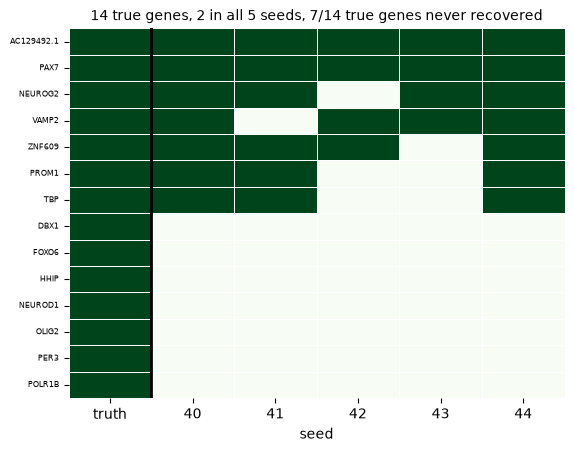

In [121]:
plot_membership(TRUE_GLOBAL_GENES, df_global_list, labels=SEEDS, only_truth = True)

In [92]:
global_sizes = []
for df in df_global_list:
    global_sizes.append(len(df.index))

In [97]:
exp_intersection = {}
for df_list, component in [(df_local_list, 'local'), (df_global_list, 'global')]:
    sizes = []
    for df in df_list:
        sizes.append(len(df.index))
    exp_intersection[component] = expected_intersection(sizes, pool = len(adata.var_names))

In [98]:
exp_intersection

{'local': 0.13623377042637114, 'global': 0.09742226453111126}

,group,k,n_subsets,obs_mean,obs_sd,exp_mean,exp_sd
0,local,2,10,17.1,0.994429,6.644318,0.682724
1,local,3,10,14.8,0.788811,1.821371,0.185434
2,local,4,5,13.6,0.547723,0.498508,0.043467
3,local,5,1,13.0,0.000000,0.136234,0.000000
0,global,2,10,16.8,1.135292,5.798864,0.452110
1,global,3,10,14.2,1.229273,1.486557,0.116441
2,global,4,5,12.4,0.894427,0.380733,0.025903
3,global,5,1,11.0,0.000000,0.097422,0.000000


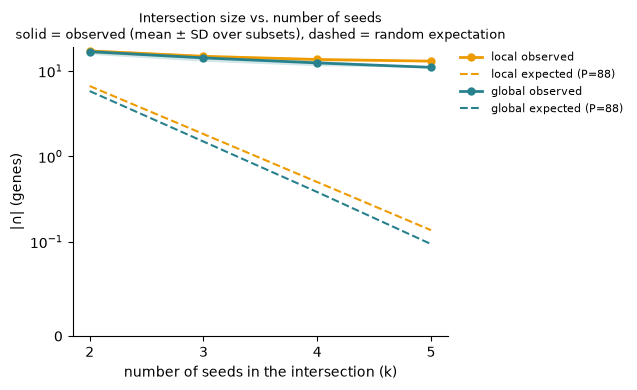

In [110]:
plot_intersection_by_k({"local": df_local_list, "global": df_global_list},
                       pool=88, log=True)

,group,k,n_subsets,p_mean,p_median,p_sd,p_min,p_max,obs_mean,exp_mean,fold_mean,method,n_iter
0,local,2,10,1.011208e-06,1.217581e-07,2.186824e-06,4.319750e-10,0.000007,17.1,6.644318,2.592472,hypergeometric,0
1,local,3,10,4.999750e-05,4.999750e-05,0.000000e+00,4.999750e-05,0.000050,14.8,1.821371,8.198717,monte-carlo,20000
2,local,4,5,4.999750e-05,4.999750e-05,0.000000e+00,4.999750e-05,0.000050,13.6,0.498508,27.442802,monte-carlo,20000
3,local,5,1,4.999750e-05,4.999750e-05,0.000000e+00,4.999750e-05,0.000050,13.0,0.136234,95.424211,monte-carlo,20000
0,global,2,10,1.126695e-07,2.266363e-09,3.272100e-07,1.404518e-10,0.000001,16.8,5.798864,2.902927,hypergeometric,0
1,global,3,10,4.999750e-05,4.999750e-05,0.000000e+00,4.999750e-05,0.000050,14.2,1.486557,9.580906,monte-carlo,20000
2,global,4,5,4.999750e-05,4.999750e-05,0.000000e+00,4.999750e-05,0.000050,12.4,0.380733,32.660072,monte-carlo,20000
3,global,5,1,4.999750e-05,4.999750e-05,0.000000e+00,4.999750e-05,0.000050,11.0,0.097422,112.910535,monte-carlo,20000


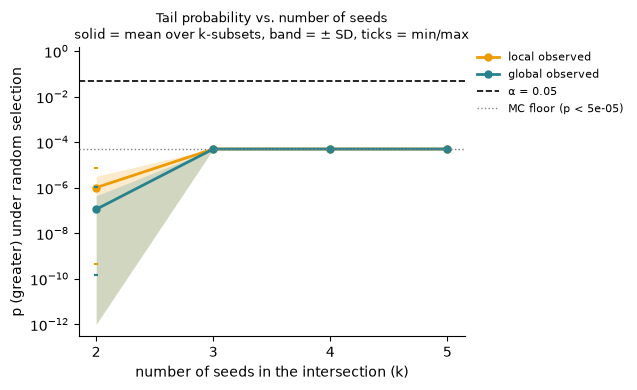

In [112]:
plot_tail_prob_by_k({"local": df_local_list, "global": df_global_list}, pool=88)

In [ ]:
for name, df_list in [("local", df_local_list), ("global", df_global_list)]:
    overlap, common = overlap_matrix(df_list, labels=SEEDS)
    print(f"--- {name} ---")
    print(overlap)
    print(f"{len(common)} genes in all {len(df_list)} seeds:", sorted(common)[:10], "\n")

In [ ]:
# The last seed's two sets. Which genes both decoders pick up is the read-out here -- the
# local/global split is only interpretable per model, not pooled over seeds.
for name, split in [(f"seed {SEEDS[-1]}", local_global_split(df_local_list[-1], df_global_list[-1]))]:
    print(name)
    for k, v in split.items():
        print(f"  {k:14s} ({len(v):2d}): {v}")

## Stability test

In [118]:
DIMS = None # "all" or None


60% cumulative variance reached with 4 dimensions:
Embedding dimensions (sorted by importance):
[9, 7, 4, 13]

60% cumulative variance reached with 5 dimensions:
Embedding dimensions (sorted by importance):
[13, 12, 7, 11, 9]


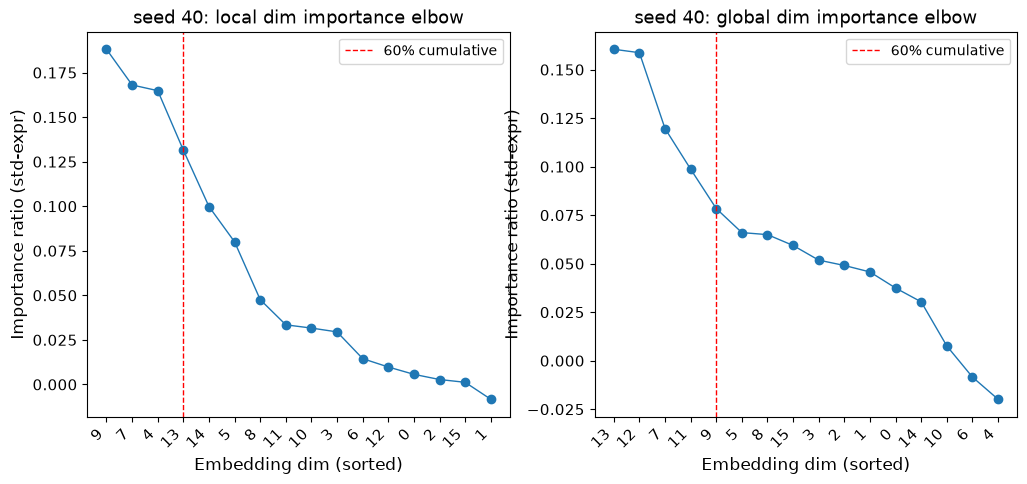

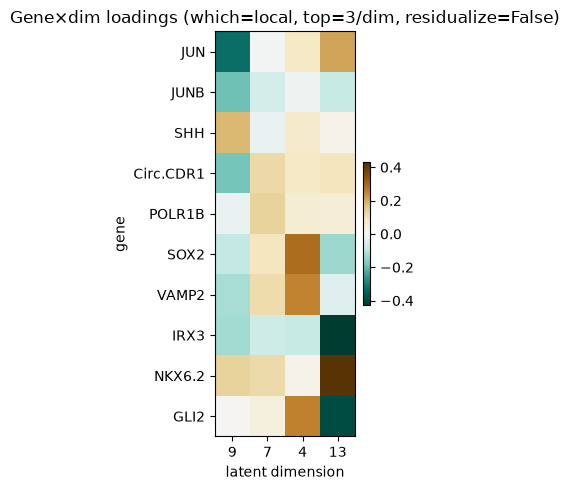

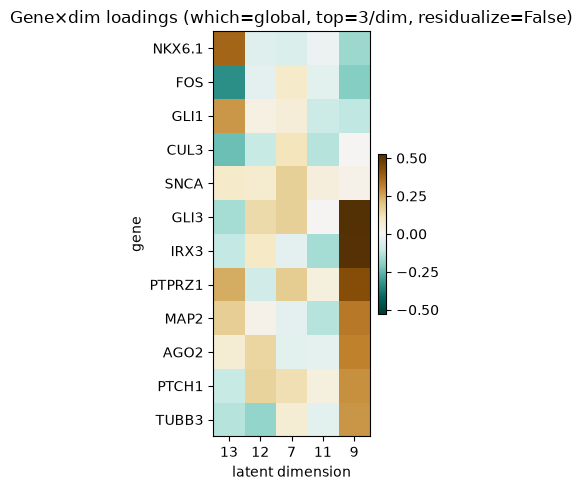

seed 40 local :  10 genes off 4 dims [np.int64(4), np.int64(7), np.int64(9), np.int64(13)]
seed 40 global:  12 genes off 5 dims [np.int64(7), np.int64(9), np.int64(11), np.int64(12), np.int64(13)]

60% cumulative variance reached with 3 dimensions:
Embedding dimensions (sorted by importance):
[9, 15, 7]

60% cumulative variance reached with 6 dimensions:
Embedding dimensions (sorted by importance):
[13, 3, 5, 14, 10, 2]


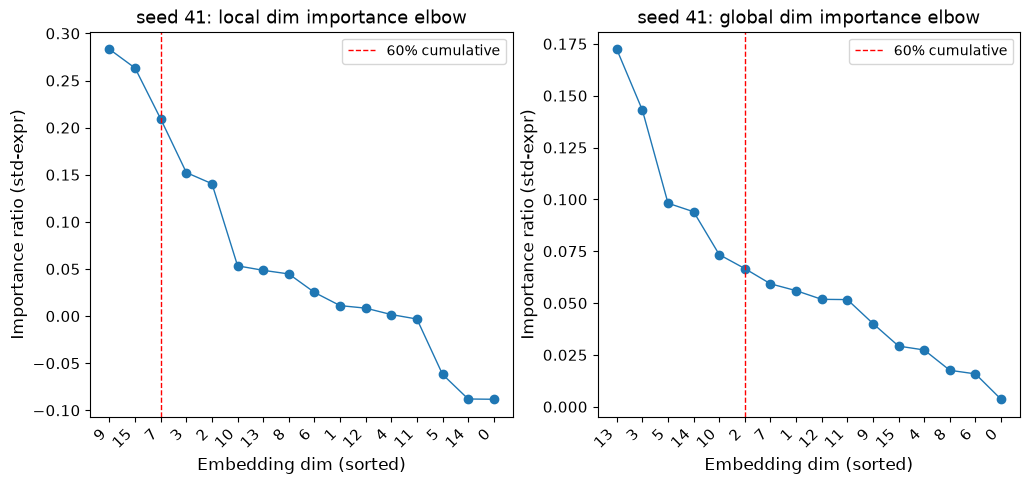

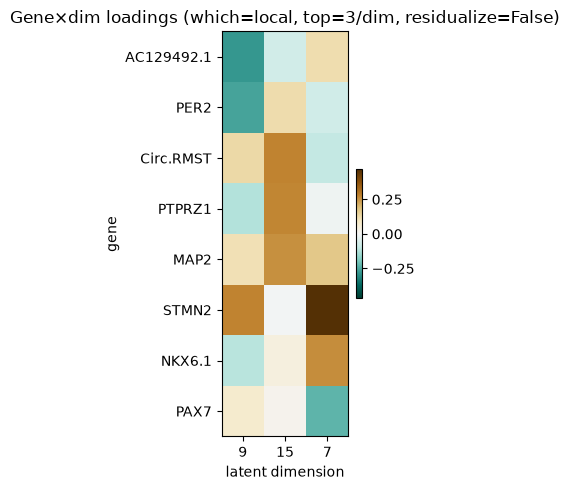

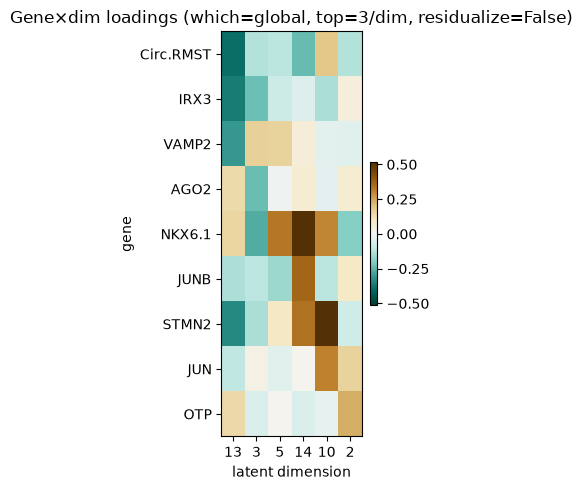

seed 41 local :   8 genes off 3 dims [np.int64(7), np.int64(9), np.int64(15)]
seed 41 global:   9 genes off 6 dims [np.int64(2), np.int64(3), np.int64(5), np.int64(10), np.int64(13), np.int64(14)]

60% cumulative variance reached with 3 dimensions:
Embedding dimensions (sorted by importance):
[12, 14, 15]

60% cumulative variance reached with 4 dimensions:
Embedding dimensions (sorted by importance):
[11, 9, 7, 14]


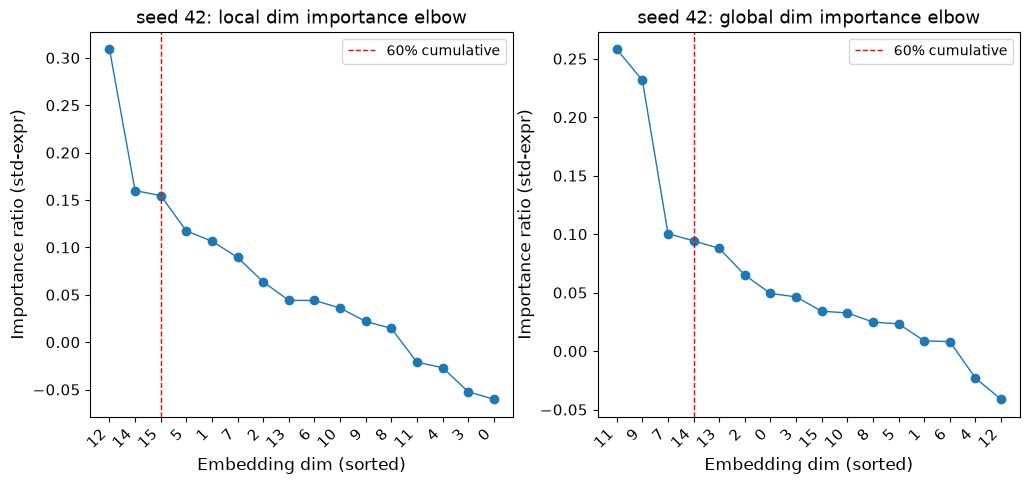

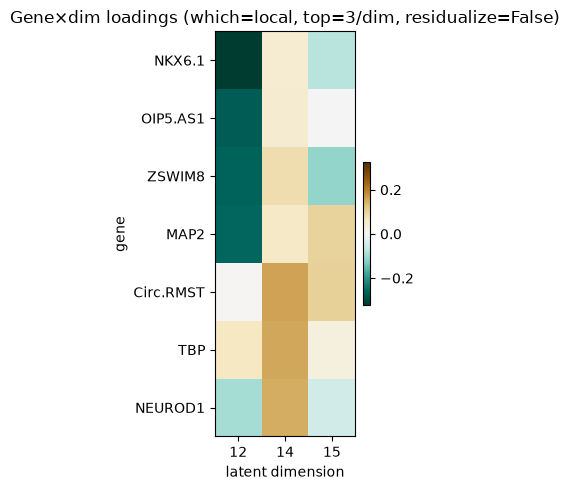

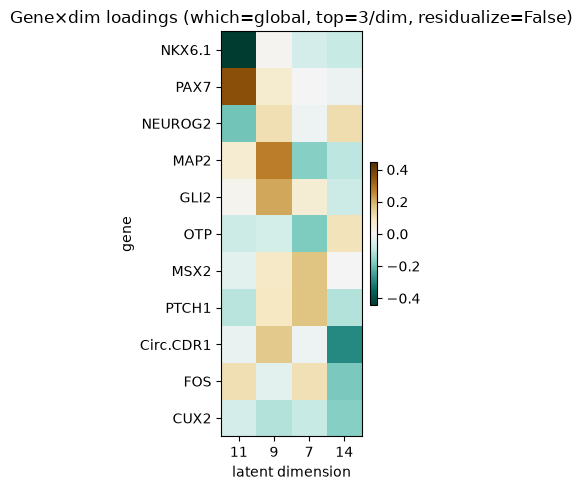

seed 42 local :   7 genes off 3 dims [np.int64(12), np.int64(14), np.int64(15)]
seed 42 global:  11 genes off 4 dims [np.int64(7), np.int64(9), np.int64(11), np.int64(14)]

60% cumulative variance reached with 3 dimensions:
Embedding dimensions (sorted by importance):
[2, 7, 9]

60% cumulative variance reached with 6 dimensions:
Embedding dimensions (sorted by importance):
[9, 13, 10, 1, 5, 6]


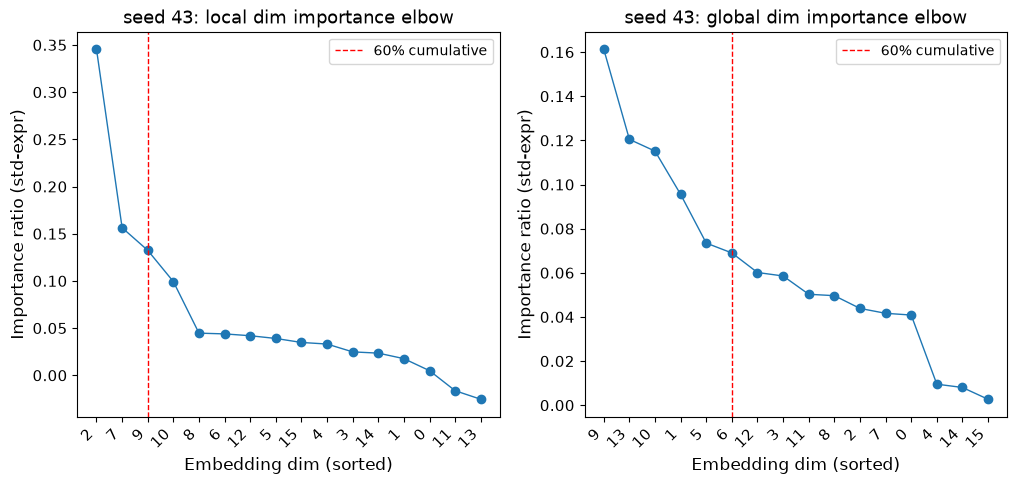

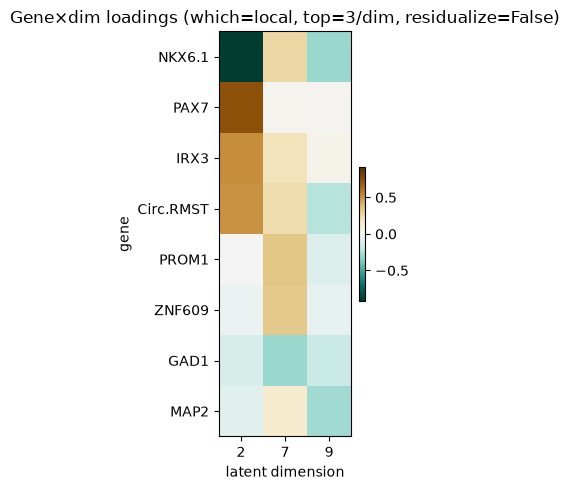

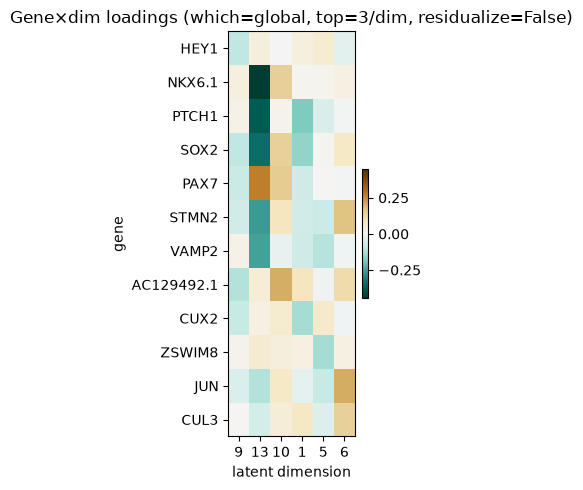

seed 43 local :   8 genes off 3 dims [np.int64(2), np.int64(7), np.int64(9)]
seed 43 global:  12 genes off 6 dims [np.int64(1), np.int64(5), np.int64(6), np.int64(9), np.int64(10), np.int64(13)]

60% cumulative variance reached with 3 dimensions:
Embedding dimensions (sorted by importance):
[3, 10, 5]

60% cumulative variance reached with 3 dimensions:
Embedding dimensions (sorted by importance):
[10, 3, 4]


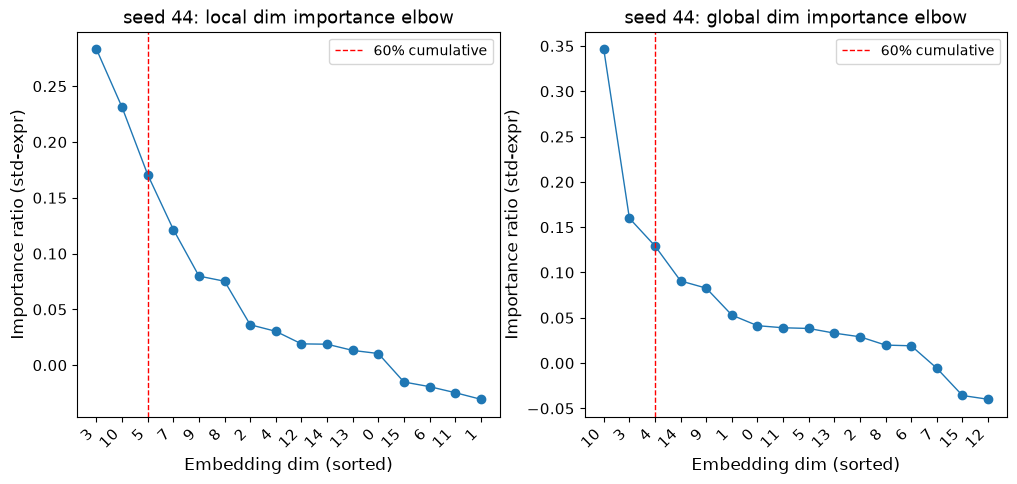

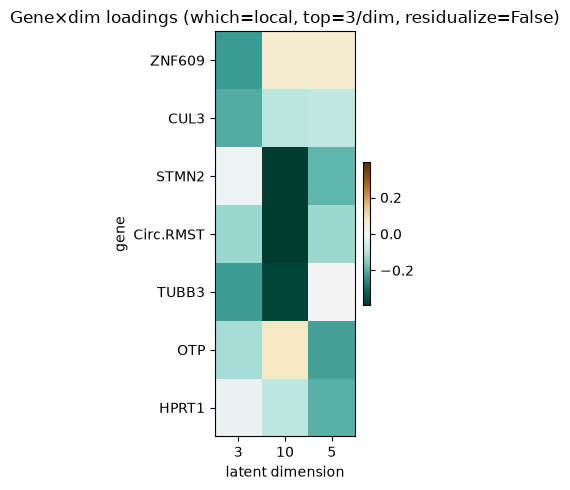

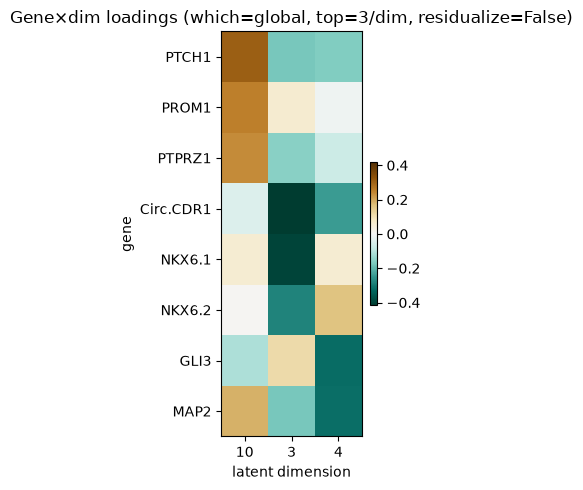

seed 44 local :   7 genes off 3 dims [np.int64(3), np.int64(5), np.int64(10)]
seed 44 global:   8 genes off 3 dims [np.int64(3), np.int64(4), np.int64(10)]


In [119]:
df_local_list, df_global_list, dims_used = collect_gene_sets(
    adata,
    models,
    SEEDS,
    dims=DIMS,
    layer_key="log1p_norm",
    n_embed=cfg0.model.n_embed,
    n_top=3,
    rank_by="loading_x_sd",
    min_frac=0.2,
    enforce_specificity=True,
    specificity_min=1.5,
    cumulative_cutoff=0.6,
    spacing=2,
    plot=True,
)

In [120]:
from statsmodels.stats.multitest import multipletests

def perm_q_corr(Z, X, dims, B=1000, seed=0):
    rng = np.random.default_rng(seed); N, F = X.shape
    Xc = (X - X.mean(0))/(X.std(0)+1e-9)
    Q = np.ones((F, len(dims)))
    for j, e in enumerate(dims):
        z = (Z[:,e]-Z[:,e].mean())/(Z[:,e].std()+1e-9)
        obs = np.abs(Xc.T @ z / N)                      # [F]
        ge = np.zeros(F)
        for _ in range(B):
            ge += (np.abs(Xc.T @ z[rng.permutation(N)] / N) >= obs)
        p = (1+ge)/(B+1)
        Q[:,j] = multipletests(p, method='fdr_bh')[1]   # BH per dimension
    return Q

In [121]:
adata.uns[f"{SEED}_local_dim_importance"]

{'dims_sorted': array([ 2,  7,  9, 10,  8,  6, 12,  5, 15,  4,  3, 14,  1,  0, 11, 13]),
 'importance_sorted': array([ 0.34539145,  0.15632982,  0.13239616,  0.09929203,  0.0446703 ,
         0.04387468,  0.04193462,  0.03903434,  0.03481285,  0.03312436,
         0.02481972,  0.02350087,  0.01764277,  0.00488831, -0.01633143,
        -0.02538086]),
 'n_dims': 16,
 'mode': 'full',
 's_key': '43_local_std_gene_loadings',
 'z_key': '43_local_emb',
 'prefix': '43',
 'use_ratio': True,
 'which': 'local',
 'dims_left': array([2, 7, 9]),
 'n_dims_left': 3,
 'cumulative_cutoff': 0.6}

In [122]:
import scipy.sparse as sparse

Z_local  = adata.obsm[f"{SEED}_local_emb"]     # [N, E]
Z_global = adata.obsm[f"{SEED}_global_emb"]    # [N, E]
X        = adata.layers["log1p_norm"]         # [N, F]  -- same layer as the loadings
if DIMS == "all":
    dims_local = adata.uns[f"{SEED}_local_dim_importance"]['dims_sorted']
    dims_global = adata.uns[f"{SEED}_global_dim_importance"]['dims_sorted']
else:
    dims_local = adata.uns[f"{SEED}_local_dim_importance"]['dims_left']
    dims_global = adata.uns[f"{SEED}_global_dim_importance"]['dims_left']
    
X = np.asarray(X.todense()) if sparse.issparse(X) else np.asarray(X)

Q_local  = perm_q_corr(Z_local,  X, dims_local)
Q_global = perm_q_corr(Z_global, X, dims_global)

In [123]:
gene_names = adata.var_names
gene_sig_local = (Q_local < 0.005).any(axis=1)   # [F] boolean, per gene
stable_local_genes = gene_names[gene_sig_local]

In [124]:
gene_sig_global = (Q_global < 0.005).any(axis=1)   # [F] boolean, per gene
stable_global_genes = gene_names[gene_sig_global]

In [125]:
len(stable_local_genes)

84

,truth,40,41,42,43,44
Circ.RMST,True,False,True,True,True,True
MAP2,True,False,True,True,True,False
NKX6.1,True,False,True,True,True,False
IRX3,True,True,False,False,True,False
PAX7,True,False,True,False,True,False
...,...,...,...,...,...,...
SATB2,True,False,False,False,False,False
SIX6,True,False,False,False,False,False
SMO,True,False,False,False,False,False
SNCA,True,False,False,False,False,False


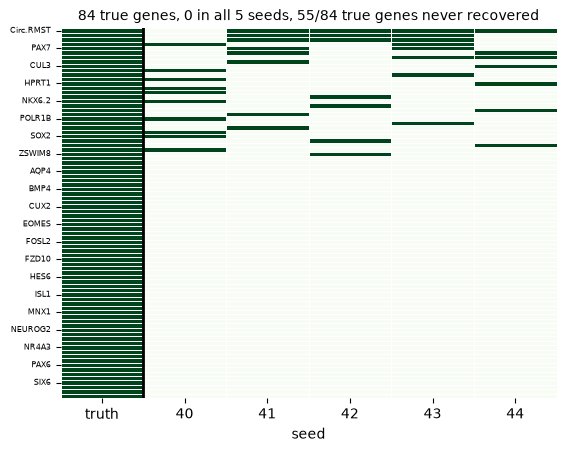

In [126]:
plot_membership(stable_local_genes, df_local_list, labels=SEEDS, only_truth = True)

,truth,40,41,42,43,44
NKX6.1,True,True,True,True,True,True
PTCH1,True,True,False,True,True,True
MAP2,True,True,False,True,False,True
AGO2,True,True,True,False,False,False
CUL3,True,True,False,False,True,False
...,...,...,...,...,...,...
SMO,True,False,False,False,False,False
TBP,True,False,False,False,False,False
TREM2,True,False,False,False,False,False
TUBB1,True,False,False,False,False,False


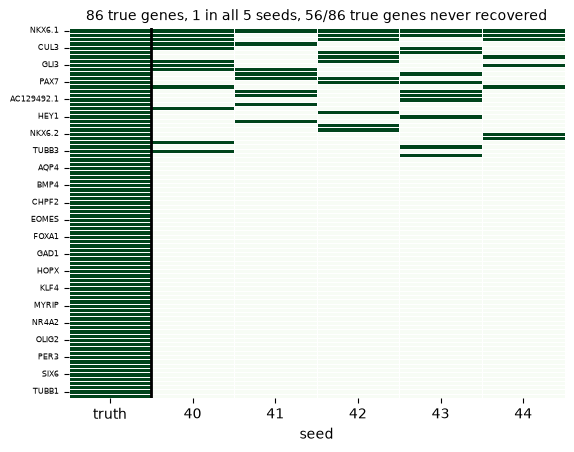

In [127]:
plot_membership(stable_global_genes, df_global_list, labels=SEEDS, only_truth = True)

In [128]:
adata

AnnData object with n_obs × n_vars = 43114 × 88
    obs: 'Cell', 'Area', 'x', 'y', 'sample', 'condition', 'organoid', 'obs_names', 'split', 'dist_to_SHH', 'SHH_zone', '_scvi_sample_key_0', '_scvi_split_key', '40_cls_horizontal', '40_cls_vertical', '41_cls_horizontal', '41_cls_vertical', '42_cls_horizontal', '42_cls_vertical', '43_cls_horizontal', '43_cls_vertical', '44_cls_horizontal', '44_cls_vertical'
    var: 'gene_ids', 'feature_types'
    uns: '_scvi_uuid', '_scvi_manager_uuid', '40_local_dim_importance', '40_global_dim_importance', '41_local_dim_importance', '41_global_dim_importance', '42_local_dim_importance', '42_global_dim_importance', '43_local_dim_importance', '43_global_dim_importance', '44_local_dim_importance', '44_global_dim_importance'
    obsm: 'spatial', '40_local_emb', '40_global_emb', '40_attn_matrix', '41_local_emb', '41_global_emb', '41_attn_matrix', '42_local_emb', '42_global_emb', '42_attn_matrix', '43_local_emb', '43_global_emb', '43_attn_matrix', '44_local_em

In [129]:
import numpy as np, pandas as pd

def coherence_prune(X, genes, loadings, keep_thresh=0.3):
    """
    X:        [N, F] log-norm expression (same layer as your loadings)
    genes:    indices (or names) of the dimension's top-k genes
    loadings: standardized loadings for those genes, same order  [k]
    Returns the genes coherent with the program, plus their scores.
    """
    Xg = X[:, genes]                                  # [N, k]
    w  = loadings / (np.abs(loadings).sum() + 1e-9)   # wmean weights

    coh = np.zeros(len(genes))
    for i in range(len(genes)):
        # leave-one-out module score: weighted mean of the OTHER genes
        mask = np.ones(len(genes), bool); mask[i] = False
        m = Xg[:, mask] @ w[mask] / (np.abs(w[mask]).sum() + 1e-9)   # [N]
        xg = Xg[:, i]
        if xg.std() < 1e-9 or m.std() < 1e-9:
            coh[i] = 0.0
        else:
            coh[i] = np.corrcoef(xg, m)[0, 1]         # coherence with the rest
    keep = coh >= keep_thresh
    return np.asarray(genes)[keep], coh

In [131]:
import numpy as np
from scipy import sparse

s, comp = '40', 'local'

# --- X: [N, 88] log-norm expression, same layer as the loadings ---
X = adata.layers['log1p_norm']
X = np.asarray(X.todense()) if sparse.issparse(X) else np.asarray(X)

# --- loadings source for this seed+component: [88 genes, E dims] ---
S = np.asarray(adata.varm[f'{s}_{comp}_std_gene_loadings'])

# --- pick the dimension's top-k genes ---
e = dims_local[0]                                  # one informative dim index (from dim_importance)
K = 15
topk = np.argsort(-np.abs(S[:, e]))[:K]      # integer gene indices into X's columns

# --- the three function arguments ---
genes    = topk                              # gene indices  [K]
loadings = S[topk, e]                        # their loadings for dim e, same order  [K]
# X is X above

kept, coh = coherence_prune(X, genes, loadings, keep_thresh=-np.inf)  # keep all, just get scores
print(np.round(np.sort(coh), 3))
print('range', coh.min().round(3), coh.max().round(3), '| n<0:', (coh<0).sum())

[-0.014 -0.011 -0.01  -0.009 -0.001  0.     0.002  0.004  0.009  0.009
  0.01   0.011  0.014  0.015  0.028]
range -0.014 0.028 | n<0: 5


In [132]:
gene_names[kept]

Index(['TREM2', 'NKX2.1', 'TBR1', 'ARG1', 'CDR1', 'ALDH1L1', 'MYRIP', 'HOPX',
       'EYA4', 'SIX6', 'FOXG1', 'CALB1', 'AIF1', 'AQP4', 'OLIG1'],
      dtype='str')

In [133]:
keep = coh >= np.quantile(coh, 0.25)  

In [136]:
gene_names[kept][keep]

Index(['TREM2', 'NKX2.1', 'TBR1', 'ARG1', 'CDR1', 'MYRIP', 'HOPX', 'SIX6',
       'CALB1', 'AIF1', 'AQP4'],
      dtype='str')

In [138]:
import numpy as np


def coherence_prune(X, genes, loadings, keep_quantile=0.75):
    """
    Prune genes from a dimension's top-k set that are not coherent with the
    rest of the program (i.e. not stable with respect to the other genes).

    Coherence for gene i = sign(loading_i) * corr(x_i, m_{-i}), where m_{-i} is
    the leave-one-out weighted module score of the OTHER genes in the set.
    The sign term orients each gene by the direction its own loading predicts,
    so correctly anti-correlated negative-loading genes score high rather than
    being wrongly dropped.

    Parameters
    ----------
    X : np.ndarray [N, F]
        Log-norm expression (same layer used for the standardized loadings).
    genes : array-like [k]
        Integer column indices into X for this dimension's top-k genes.
    loadings : array-like [k]
        Standardized loadings of those genes on this dimension, same order.
    keep_quantile : float
        Keep genes whose coherence is >= this quantile of the coherence
        distribution. 0.75 keeps the upper quartile.

    Returns
    -------
    kept_genes : np.ndarray
        Subset of `genes` retained (upper-quartile coherence).
    coh : np.ndarray [k]
        Coherence score per input gene, aligned with `genes`.
    """
    genes = np.asarray(genes)
    loadings = np.asarray(loadings, dtype=float)
    Xg = X[:, genes]                                  # [N, k]
    w = loadings / (np.abs(loadings).sum() + 1e-9)    # signed wmean weights

    k = len(genes)
    coh = np.zeros(k)
    for i in range(k):
        mask = np.ones(k, bool)
        mask[i] = False
        # leave-one-out signed module score of the other genes
        denom = np.abs(w[mask]).sum() + 1e-9
        m = Xg[:, mask] @ w[mask] / denom             # [N]
        xg = Xg[:, i]
        if xg.std() < 1e-9 or m.std() < 1e-9:
            coh[i] = 0.0
        else:
            r = np.corrcoef(xg, m)[0, 1]
            coh[i] = np.sign(loadings[i]) * r          # orient by loading sign

    thresh = np.quantile(coh, keep_quantile)
    keep = coh >= thresh
    return genes[keep], coh

In [141]:
len(genes)

15

In [139]:
kept, coh = coherence_prune(X, genes, loadings)
for g, c in sorted(zip(adata.var_names[genes], coh), key=lambda t: t[1]):
    print(f"{c:+.3f}  {g}")

-0.011  AQP4
-0.010  CALB1
-0.009  NKX2.1
-0.002  TBR1
-0.001  MYRIP
+0.000  ARG1
+0.004  TREM2
+0.009  HOPX
+0.009  OLIG1
+0.010  ALDH1L1
+0.011  FOXG1
+0.014  CDR1
+0.014  EYA4
+0.015  SIX6
+0.028  AIF1


In [144]:
gene_names[kept]

Index(['CDR1', 'EYA4', 'SIX6', 'AIF1'], dtype='str')